In [11]:
import pandas as pd
import sqlite3
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Matching Parents and Children with SQL in Python: Estimating IGE and Life-Cycle Bias

## Introduction
Intergenerational income elasticity, or IGE, measures the strength of the relationship between parental income and children’s income, a core metric for studying economic mobility.
A key challenge for IGE estimation comes from temporary income shocks. Income observed in a single year mixes stable long-run economic status with random gains or losses. This measurement error creates life-cycle bias, a form of attenuation bias that pushes the estimated IGE toward zero.
This tutorial uses simulated longitudinal panel data and SQL operations inside Python. Using family and individual identifiers, we build two matched parent-child samples: one based on single-year income and one based on multi-year average income. We compare the two IGE estimates to demonstrate life-cycle bias.

In [12]:
np.random.seed(6443)
n_families = 300

family_id = np.repeat(np.arange(n_families), 2)
person_id = np.arange(n_families * 2)
is_parent = np.tile([1,0], n_families)

years = [2015,2016,2017,2018,2019]
data_list = []
for y in years:
    age_base = np.where(is_parent, 42, 18)
    age = age_base + (y - 2015)
    permanent_income = np.where(is_parent,
                                np.random.lognormal(10, 0.6, n_families*2),
                                np.random.lognormal(9, 0.6, n_families*2)
                               )
    shock = np.random.lognormal(0, 0.3, n_families*2)
    income = permanent_income * shock
    data_list.append(pd.DataFrame({
        "family_id": family_id,
        "person_id": person_id,
        "is_parent": is_parent,
        "year": y,
        "age": age,
        "income": income
    }))

df = pd.concat(data_list).reset_index(drop=True)

con = sqlite3.connect(":memory:")
df.to_sql("panel", con, index=False, if_exists="replace")

3000

# Single-year parent-child match
The panel data recorded the annual year income repeatedly for everyone. family_id is for grouping different families, is_parent marks whether the sample is parents or not.
We use SQL INNER JOIN to connect the panel table to itself according to family_id., filtering the parent-child matched samples that have observable records in 2017. This group of simple match sample only rely on the income data for this year. Its shortcoming is very obvious: one year’s income contains the unpredictable temporary income shock.

In [13]:
sql_single = "SELECT parent.family_id, parent.income AS parent_income_single, child.income AS child_income_single FROM panel parent INNER JOIN panel child ON parent.family_id = child.family_id WHERE parent.is_parent = 1 AND child.is_parent = 0 AND parent.year = 2017 AND child.year = 2017"
df_single = pd.read_sql(sql_single, con)

## GROUP BY aggregation and multi-year matched sample
In order to reduce noise, we aggregate everyone’s income from 2015 to 2019. We use GROUP BY using person_id, and use the AVG() to calculate the average income. The random shocks which are either positive or negative would offset each other as time goes by, thus the average income would be more approximate to permanent long term income.
We created a new table for individuals average income, again using family_id to run INNER JOIN, and matched parents and children again.
This step fully shows the core SQL tools: SELECT, GROUP BY, aggregation, and INNER JOIN.

In [14]:
sql_avg_step = "SELECT person_id, family_id, is_parent, AVG(income) AS avg_income FROM panel GROUP BY person_id, family_id, is_parent"
df_person_avg = pd.read_sql(sql_avg_step, con)
df_person_avg.to_sql("person_avg_table", con, index=False, if_exists="replace")

600

In [15]:
sql_avg_match = "SELECT parent.family_id, parent.avg_income AS parent_income_avg, child.avg_income AS child_income_avg FROM person_avg_table parent INNER JOIN person_avg_table child ON parent.family_id = child.family_id WHERE parent.is_parent = 1 AND child.is_parent = 0"
df_avg = pd.read_sql(sql_avg_match, con)

## Log-log regression and IGE estimation
We use standard log-log OLS model to estimate IGE:
\log(Y_{child})=\alpha+\beta \log(Y_{parent})+\epsilon
The coefficient beta is the IGE. It represents the percentage change in children’s income with the every 1% increase in parents’ income. The log transformation can handle the right-skewed feature of the income data, and fits the standard  interpretation of elasticity.
The results are:
Single-year IGE: −0.0477
Multi-year average IGE: −0.0776
Here the coefficients are negative since the parent’s and children’s permanent income in the simulated data is independent and randomly generated. The role of lifecycle bias is regardless of the sign, since the random noise would always push the estimated coefficients towards 0. The result of Singe-year IGE is -0.0477, which is closer to 0. After averaging, it eliminates some of the random noise, and the result becomes-0.0776, which is more far away from 0. This change shows that noise has compressed the association towardzero.


In [16]:
df_single

,family_id,parent_income_single,child_income_single
0,0,11934.104212,10814.543427
1,1,27319.706965,14792.038372
2,2,3042.552726,47325.714455
3,3,13553.266033,3368.112879
4,4,18186.979842,5408.571455
...,...,...,...
295,295,14876.233906,37029.077318
296,296,13698.746409,6418.939184
297,297,53376.287295,7724.702143
298,298,26218.401708,1333.854533


In [17]:
df_avg

,family_id,parent_income_avg,child_income_avg
0,0,17348.244463,11346.096136
1,1,18479.294538,8021.037155
2,2,19900.592770,19825.940601
3,3,23280.066531,7428.343338
4,4,24840.963439,13022.989134
...,...,...,...
295,295,30561.679279,17556.263275
296,296,32083.409652,10284.095030
297,297,35474.207621,7389.273167
298,298,22430.464981,6750.291955


In [18]:
df_single['log_parent'] = np.log(df_single['parent_income_single'])
df_single['log_child'] = np.log(df_single['child_income_single'])
df_avg['log_parent'] = np.log(df_avg['parent_income_avg'])
df_avg['log_child'] = np.log(df_avg['child_income_avg'])
model_single = sm.OLS(df_single['log_child'], sm.add_constant(df_single['log_parent'])).fit()
model_avg = sm.OLS(df_avg['log_child'], sm.add_constant(df_avg['log_parent'])).fit()
print(model_single.params)
print(model_avg.params)

const         9.500348
log_parent   -0.047664
dtype: float64
const         9.952259
log_parent   -0.077610
dtype: float64


## Discussion and Takeaway
In this simulation data, parents' and children's permanent income are generated independently. We only shows lifecycle bias this mechanism, not a real-world positive intergenerational relationship. Comparing the data of the two groups of IGE, we can see the lifecycle bias brings by the temporarily supply shock. There exist measuring bias of single-year income, which would weaken the obsearved association between permanent parental income and child income, moving IGE towards 0. The averaging of multiple years income can reduce the variance of the temporary fluctuation, the average income is a better measurement of the long-term permanent economic level. In this result, removing the noise makes the coefficient move away from 0, from -0.0477 to -0.0776. This proves the lifecycle bias that noise would shrink the strength of underlying relationship, regardless of whether the sign is positive or negative. When researching the intergenerational mobility, the mulli-year averaged income makesthe IGE more reliable than single year.

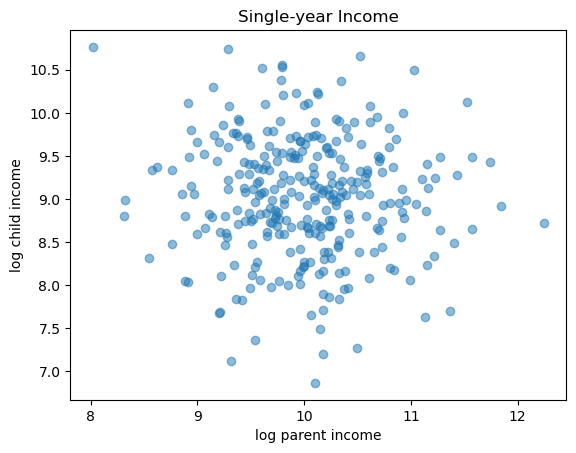

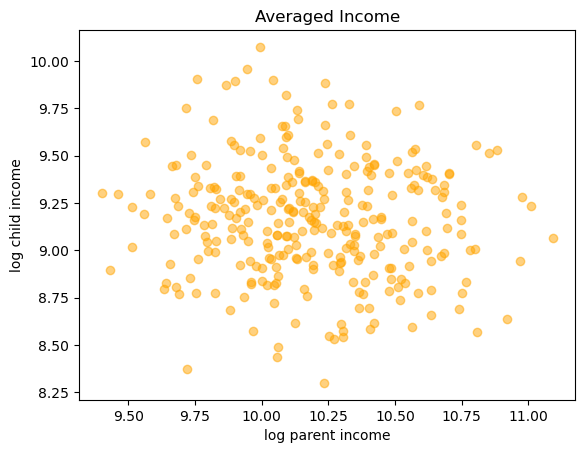

In [19]:
import matplotlib.pyplot as plt
plt.scatter(df_single['log_parent'], df_single['log_child'], alpha=0.5)
plt.xlabel("log parent income")
plt.ylabel("log child income")
plt.title("Single-year Income")
plt.show()
plt.scatter(df_avg['log_parent'], df_avg['log_child'], alpha=0.5, color="orange")
plt.xlabel("log parent income")
plt.ylabel("log child income")
plt.title("Averaged Income")
plt.show()